### 치이카와 유튜브 EDA

-> 원본 CSV와 1차 정제 노트북은 변경x 
<br> -> 이 노트북은 CSV를 읽기만 하고, `.copy()`로 만든 분석용 데이터프레임에 파생변수만 추가

국내 생산의 조작적 정의는 **제목에 한글이 있고 히라가나·가타카나가 없는 영상**이다. 시청자 국가가 아니라 제목 언어 기준이다.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path(r"C:/Users/user/DATA_MKT_260920/data.project/KDT_Integral_Data_Project/02_csv/01_youtube")
ANALYSIS_CSV = ROOT / "영상" / "youtube_analysis_merged.csv"
AUDIT_CSV = ROOT / "영상" / "youtube_relevance_audit_merged.csv"

df_merged = pd.read_csv(ANALYSIS_CSV, encoding="utf-8-sig")
df_relevance_audit = pd.read_csv(AUDIT_CSV, encoding="utf-8-sig")

original_analysis_shape = df_merged.shape
original_audit_shape = df_relevance_audit.shape
original_analysis_ids = df_merged["video_id"].tolist()
original_audit_ids = df_relevance_audit["video_id"].tolist()
print("원본 analysis", original_analysis_shape)
print("원본 relevance", original_audit_shape)


Duplicate key in file WindowsPath('C:/Users/user/AppData/Local/Programs/Python/Python311/Lib/site-packages/matplotlib/mpl-data/matplotlibrc'), line 269 ('font.family:  sans-serif')


원본 analysis (13383, 9)
원본 relevance (14667, 8)


## 데이터 품질 확인

1차 정제 노트북은 좋아요·댓글 결측을 0으로 채웠다. 이번 요청은 그 대체를 하지 않으므로, 분석은 CSV 원본의 결측을 유지한다. `publish_at`의 UTC를 한국 시간으로 읽는 변환과 `duration`의 초 변환은 새 열로만 만든다.


In [2]:
quality = pd.DataFrame({
    "항목": [
        "행 수", "video_id 중복", "video_id 결측",
        "view_count 결측", "view_count 0", "view_count 음수",
        "like_count 결측", "like_count 음수",
        "comment_count 결측", "comment_count 음수",
        "publish_at 결측", "title 결측",
    ],
    "df_merged": [
        len(df_merged),
        int(df_merged["video_id"].duplicated().sum()),
        int(df_merged["video_id"].isna().sum()),
        int(df_merged["view_count"].isna().sum()),
        int((df_merged["view_count"] == 0).sum()),
        int((df_merged["view_count"] < 0).sum()),
        int(df_merged["like_count"].isna().sum()),
        int((df_merged["like_count"].dropna() < 0).sum()),
        int(df_merged["comment_count"].isna().sum()),
        int((df_merged["comment_count"].dropna() < 0).sum()),
        int(df_merged["publish_at"].isna().sum()),
        int(df_merged["title"].isna().sum()),
    ],
})
audit_status = df_relevance_audit["relevance_status"].value_counts(dropna=False)
print(quality.to_string(index=False))
print("\nrelevance_status")
print(audit_status.to_string())
print("audit video_id 중복", int(df_relevance_audit["video_id"].duplicated().sum()))
print("duration 결측", int(df_relevance_audit["duration"].isna().sum()))
print("review_details_unavailable", int((df_relevance_audit["relevance_status"] == "review_details_unavailable").sum()))


              항목  df_merged
             행 수      13383
     video_id 중복          0
     video_id 결측          0
   view_count 결측          0
    view_count 0          0
   view_count 음수          0
   like_count 결측        743
   like_count 음수          0
comment_count 결측       1265
comment_count 음수          0
   publish_at 결측          0
        title 결측          0

relevance_status
relevance_status
relevant           13383
review_no_match     1284
audit video_id 중복 0
duration 결측 0
review_details_unavailable 0


## 분석용 복사본과 관련성 분리

`review_no_match`는 분석 대상에서 빼되 원본에서는 지우지 않고 `df_excluded`에 둔다. `relevant`만 `video_id`로 1:1 결합한다.


In [3]:
df_analysis = df_merged.copy()
df_audit_all = df_relevance_audit.copy()

df_excluded = df_audit_all.loc[df_audit_all["relevance_status"] != "relevant"].copy()
df_audit = df_audit_all.loc[df_audit_all["relevance_status"] == "relevant"].copy()

print("제외 review_no_match", len(df_excluded), df_excluded["relevance_status"].value_counts().to_dict())
print("분석 relevance", len(df_audit))

key_check = df_analysis.merge(df_audit[["video_id"]], on="video_id", how="outer", indicator=True)
print(key_check["_merge"].value_counts().to_string())

df = df_analysis.merge(df_audit, on="video_id", how="inner", validate="one_to_one")
print("결합 후", df.shape)
assert len(df) == len(df_analysis) == len(df_audit)
assert df["video_id"].is_unique


제외 review_no_match 1284 {'review_no_match': 1284}
분석 relevance 13383
_merge
both          13383
left_only         0
right_only        0
결합 후 (13383, 16)


## 파생변수

`like_rate`, `comment_rate`, `engagement_rate`는 분모가 0이거나 분자 지표가 결측이면 계산하지 않는다. 좋아요 또는 댓글이 비어 있으면 참여율도 비운다.


In [4]:
def duration_to_seconds(value):
    if pd.isna(value):
        return pd.NA
    match = re.fullmatch(r"PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?", str(value))
    if not match:
        return pd.NA
    hours, minutes, seconds = (int(part) if part else 0 for part in match.groups())
    return hours * 3600 + minutes * 60 + seconds

df["publish_at_kst"] = pd.to_datetime(df["publish_at"], utc=True).dt.tz_convert("Asia/Seoul")
df["collected_at_kst"] = pd.to_datetime(df["collected_at"], utc=True).dt.tz_convert("Asia/Seoul")
df["year"] = df["publish_at_kst"].dt.year
df["year_month"] = df["publish_at_kst"].dt.strftime("%Y-%m")
df["duration_sec"] = df["duration"].map(duration_to_seconds).astype("Int64")
df["is_short_60"] = df["duration_sec"].le(60)

df["like_rate"] = (df["like_count"] / df["view_count"] * 100).where(df["view_count"].gt(0) & df["like_count"].notna())
df["comment_rate"] = (df["comment_count"] / df["view_count"] * 100).where(df["view_count"].gt(0) & df["comment_count"].notna())
df["engagement_rate"] = ((df["like_count"] + df["comment_count"]) / df["view_count"] * 100).where(
    df["view_count"].gt(0) & df["like_count"].notna() & df["comment_count"].notna()
)

print("duration_sec 변환 실패", int(df["duration_sec"].isna().sum()))
print("publish_at_kst", df["publish_at_kst"].min(), "~", df["publish_at_kst"].max())
print("collected_at_kst", df["collected_at_kst"].min(), "~", df["collected_at_kst"].max())
print("like_rate 계산 가능", int(df["like_rate"].notna().sum()), "/ comment_rate", int(df["comment_rate"].notna().sum()), "/ engagement", int(df["engagement_rate"].notna().sum()))


duration_sec 변환 실패 0
publish_at_kst 2022-01-03 16:04:09+09:00 ~ 2026-10-26 19:00:08+09:00
collected_at_kst 2026-10-26 19:07:25.207058+09:00 ~ 2026-10-27 20:28:42.016265+09:00
like_rate 계산 가능 12640 / comment_rate 12118 / engagement 11470


## 국내 제목 부분집합

수집 검색은 한국 시간 연도와 `regionCode=KR`을 썼지만, 결과에는 일본어 제목이 포함되어 있다. 네 가지 분석은 한글 제목만 있는 영상에 적용한다.


In [5]:
title = df["title"].fillna("")
df["has_hangul"] = title.str.contains(r"[가-힣]", regex=True)
df["has_kana"] = title.str.contains("[ぁ-んァ-ン]", regex=True)
df["is_korean_title"] = df["has_hangul"] & ~df["has_kana"]

scope_counts = pd.DataFrame({
    "구분": ["전체 relevant", "한글만", "한글+가나", "한글 없음"],
    "영상 수": [
        len(df),
        int(df["is_korean_title"].sum()),
        int((df["has_hangul"] & df["has_kana"]).sum()),
        int((~df["has_hangul"]).sum()),
    ],
})
print(scope_counts.to_string(index=False))

df_kr = df.loc[df["is_korean_title"]].copy()
print("국내 분석 대상", len(df_kr))
print("국내 집합에서 제외", len(df) - len(df_kr), "건. 사유: 제목이 국내 생산 프록시(한글만)에 해당하지 않음")


         구분  영상 수
전체 relevant 13383
        한글만  8941
      한글+가나   982
      한글 없음  3460
국내 분석 대상 8941
국내 집합에서 제외 4442 건. 사유: 제목이 국내 생산 프록시(한글만)에 해당하지 않음


## 제목 단어 분포와 분류 기준

분류 사전에 넣기 전에 제목의 한글 단어 빈도를 확인한다. 콘텐츠 유형은 제목만 본다. 설명에 있는 성우 크레딧이 본편 공개 영상을 더빙 창작으로 분류하는 것을 막기 위해서다. 캐릭터명과 작품명은 제목, 설명, 태그를 함께 본다.

`인형계`는 상품 언박싱과 다른 인형 상황극이라 별도 유형으로 둔다. `인형`은 `인형계`를 포함하지 않는다. `치이카와`와 `먼작귀`는 작품명으로 분리한다. `시사`는 `시리즈`를 제외한다.


In [6]:
token_counts = (
    df_kr["title"].fillna("").str.findall(r"[가-힣]{2,}")
    .explode()
    .value_counts()
    .head(40)
    .rename_axis("제목 단어")
    .reset_index(name="영상 수")
)
print(token_counts.to_string(index=False))


    제목 단어  영상 수
     치이카와  8728
      먼작귀  2194
      인형계  1861
       컨셉  1824
       쇼츠  1589
       추천  1529
       감기  1347
       조이  1142
     브이로그   444
      우사기   434
      귀여운   410
       가챠   401
     하치와레   395
      산리오   354
       인형   338
      랜덤깡   323
      피규어   291
      언박싱   291
       일본   271
       작고   270
       먼가   262
     인형뽑기   262
       뽑기   257
       굿즈   248
       녀석   244
      오타쿠   243
      만들기   243
       포장   236
     전편공개   235
     알고리즘   184
     포카포장   178
      콜라보   168
       신상   166
       도쿄   160
먼가작고귀여운녀석   157
       리뷰   155
      아이브   150
       키링   149
       랜덤   145
      극장판   137


In [7]:
CONTENT_RULES = [
    ("인형계·상황극", ["인형계"]),
    ("상품·수집", ["키링", "피규어", "가챠", "뽑기", "언박싱", "언박", "굿즈", "하울", "개봉기", "택배"]),
    ("오프라인", ["팝업", "카페", "콜라보", "다이소", "편의점", "성지"]),
    ("작품·영상", ["전편공개", "극장판", "극장", "영화", "애니", "최신화"]),
    ("창작·더빙", ["그리기", "그림", "더빙", "성우", "팬아트"]),
    ("일상", ["브이로그", "vlog", "일상", "asmr", "먹방"]),
]
CONTENT_PRIORITY = [name for name, _ in CONTENT_RULES]

CHARACTER_RULES = [
    ("하치와레", r"하치와레"),
    ("우사기", r"우사기"),
    ("모몽가", r"모몽가"),
    ("랏코", r"랏코"),
    ("쿠리만쥬", r"쿠리만쥬"),
    ("시사", r"시사(?!리즈)"),
    ("아노코", r"아노코"),
    ("갑옷씨", r"갑옷씨"),
    ("데카츠요", r"데카츠요"),
    ("파자마파티즈", r"파자마\s*파티즈|파자마즈"),
    ("카니", r"(?<![가-힣])카니(?![가-힣])"),
]
SERIES_RULES = [
    ("치이카와", r"치이카와"),
    ("먼작귀", r"먼작귀"),
]

df_kr["search_text"] = (
    df_kr["title"].fillna("") + "\n"
    + df_kr["description"].fillna("") + "\n"
    + df_kr["tags"].fillna("")
)

for name, keywords in CONTENT_RULES:
    pattern = "|".join(re.escape(word) for word in keywords)
    df_kr[f"type_{name}"] = df_kr["title"].fillna("").str.contains(pattern, case=False, na=False)

df_kr["type_상품·수집"] = df_kr["type_상품·수집"] | df_kr["title"].fillna("").str.contains(r"인형(?!계)", na=False)

type_cols = [f"type_{name}" for name, _ in CONTENT_RULES]

def join_labels(row, columns, labels):
    picked = [label for column, label in zip(columns, labels) if row[column]]
    return "|".join(picked)

df_kr["content_type"] = df_kr.apply(lambda row: join_labels(row, type_cols, CONTENT_PRIORITY), axis=1)
df_kr["content_type"] = df_kr["content_type"].replace("", pd.NA)

def primary_type(value):
    if pd.isna(value) or value == "":
        return "미분류"
    found = set(value.split("|"))
    for name in CONTENT_PRIORITY:
        if name in found:
            return name
    return "미분류"

df_kr["primary_content_type"] = df_kr["content_type"].map(primary_type)

for name, pattern in CHARACTER_RULES:
    df_kr[f"char_{name}"] = df_kr["search_text"].str.contains(pattern, case=False, na=False, regex=True)
char_cols = [f"char_{name}" for name, _ in CHARACTER_RULES]
char_labels = [name for name, _ in CHARACTER_RULES]
df_kr["character"] = df_kr.apply(lambda row: join_labels(row, char_cols, char_labels), axis=1)
df_kr["character"] = df_kr["character"].replace("", pd.NA)

for name, pattern in SERIES_RULES:
    df_kr[f"series_{name}"] = df_kr["search_text"].str.contains(pattern, case=False, na=False, regex=True)
series_cols = [f"series_{name}" for name, _ in SERIES_RULES]
series_labels = [name for name, _ in SERIES_RULES]
df_kr["series_name"] = df_kr.apply(lambda row: join_labels(row, series_cols, series_labels), axis=1)
df_kr["series_name"] = df_kr["series_name"].replace("", pd.NA)

rule_rows = []
for name, keywords in CONTENT_RULES:
    shown = ", ".join(keywords)
    if name == "상품·수집":
        shown += ", 인형(인형계 제외)"
    rule_rows.append({"구분": "콘텐츠 유형", "라벨": name, "기준": shown, "해당 영상 수": int(df_kr[f"type_{name}"].sum())})
for name, pattern in CHARACTER_RULES:
    rule_rows.append({"구분": "캐릭터", "라벨": name, "기준": pattern, "해당 영상 수": int(df_kr[f"char_{name}"].sum())})
for name, pattern in SERIES_RULES:
    rule_rows.append({"구분": "작품명", "라벨": name, "기준": pattern, "해당 영상 수": int(df_kr[f"series_{name}"].sum())})
rule_table = pd.DataFrame(rule_rows)
print(rule_table.to_string(index=False))
print("\n복수 유형 영상", int(df_kr["content_type"].fillna("").str.contains("|", regex=False).sum()))
print("특정 캐릭터 언급 영상", int(df_kr["character"].notna().sum()))
print("미분류", int((df_kr["primary_content_type"] == "미분류").sum()))


    구분      라벨                                                    기준  해당 영상 수
콘텐츠 유형 인형계·상황극                                                   인형계     1862
콘텐츠 유형   상품·수집 키링, 피규어, 가챠, 뽑기, 언박싱, 언박, 굿즈, 하울, 개봉기, 택배, 인형(인형계 제외)     2186
콘텐츠 유형    오프라인                             팝업, 카페, 콜라보, 다이소, 편의점, 성지      570
콘텐츠 유형   작품·영상                            전편공개, 극장판, 극장, 영화, 애니, 최신화      460
콘텐츠 유형   창작·더빙                                  그리기, 그림, 더빙, 성우, 팬아트      135
콘텐츠 유형      일상                              브이로그, vlog, 일상, asmr, 먹방     1119
   캐릭터    하치와레                                                  하치와레     1346
   캐릭터     우사기                                                   우사기     1142
   캐릭터     모몽가                                                   모몽가      378
   캐릭터      랏코                                                    랏코      211
   캐릭터    쿠리만쥬                                                  쿠리만쥬      233
   캐릭터      시사                                              시사(?

## 분석 1. 콘텐츠 생산 추이

질문: 국내 유튜브에서 치이카와 관련 콘텐츠 생산은 시간에 따라 어떻게 변했는가?

게시량은 이 수집 표본의 영상 수다. 국내 전체 관심도와 같은 값으로 보지 않는다. 2026년은 수집일이 2026-10-27이라 1~10월만 포함된다.


      전체 relevant  한글 제목  한글 제목 비율
year                              
2022         1945    335     0.172
2023         2834   1277     0.451
2024         2710   2082     0.768
2025         3012   2673     0.887
2026         2882   2574     0.893

월별 앞 3개월
            영상수  활동채널수
year_month            
2022-01       1      1
2022-02       2      2
2022-03       3      3
월별 마지막 3개월
            영상수  활동채널수
year_month            
2026-08     184    131
2026-09     325    203
2026-10     421    221

연도별 생산 채널 수
year
2022     155
2023     598
2024    1068
2025    1554
2026    1258

연도별 제목에 인형계가 있는 영상
year
2022       0
2023      13
2024     266
2025    1149
2026     434


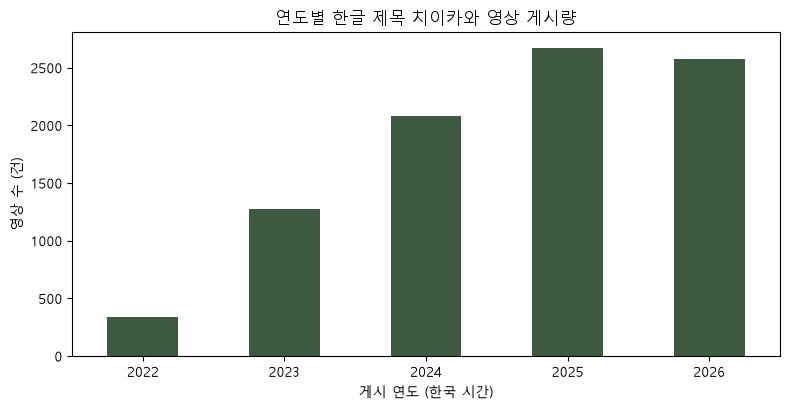

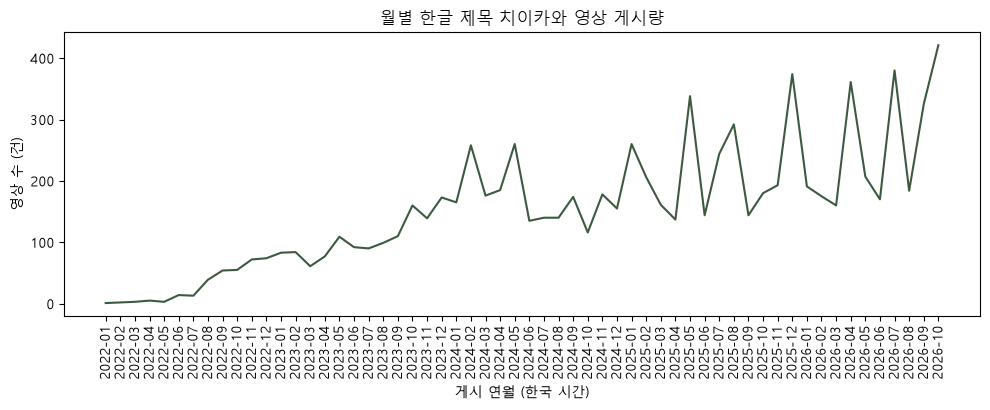

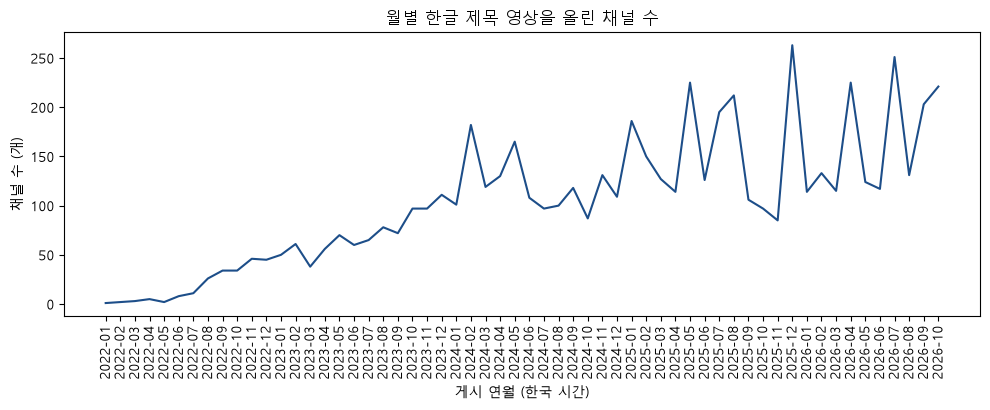

In [8]:
yearly_all = df.groupby("year").size().rename("전체 relevant")
yearly_kr = df_kr.groupby("year").size().rename("한글 제목")
yearly = pd.concat([yearly_all, yearly_kr], axis=1).fillna(0).astype(int)
yearly["한글 제목 비율"] = (yearly["한글 제목"] / yearly["전체 relevant"]).round(3)
print(yearly)

monthly = df_kr.groupby("year_month").agg(영상수=("video_id", "size"), 활동채널수=("channel_id", "nunique"))
print("\n월별 앞 3개월")
print(monthly.head(3))
print("월별 마지막 3개월")
print(monthly.tail(3))

yearly_channels = df_kr.groupby("year")["channel_id"].nunique().rename("생산 채널 수")
print("\n연도별 생산 채널 수")
print(yearly_channels.to_string())
print("\n연도별 제목에 인형계가 있는 영상")
print(df_kr.groupby("year")["type_인형계·상황극"].sum().astype(int).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
yearly["한글 제목"].plot(kind="bar", ax=ax, color="#3d5a40")
ax.set_title("연도별 한글 제목 치이카와 영상 게시량")
ax.set_xlabel("게시 연도 (한국 시간)")
ax.set_ylabel("영상 수 (건)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend().remove()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly["영상수"], color="#3d5a40", label="영상 수")
ax.set_title("월별 한글 제목 치이카와 영상 게시량")
ax.set_xlabel("게시 연월 (한국 시간)")
ax.set_ylabel("영상 수 (건)")
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index, monthly["활동채널수"], color="#1d4e89", label="활동 채널 수")
ax.set_title("월별 한글 제목 영상을 올린 채널 수")
ax.set_xlabel("게시 연월 (한국 시간)")
ax.set_ylabel("채널 수 (개)")
ax.tick_params(axis="x", labelrotation=90)
fig.tight_layout()
plt.show()


## 분석 2. 콘텐츠 유형별 이용자 반응

질문: 어떤 유형에서 이용자 반응이 상대적으로 높은가?

막대그래프의 유형은 우선순위가 있는 대표 유형이다. 한 영상이 여러 키워드에 걸치면 `인형계·상황극 > 상품·수집 > 오프라인 > 작품·영상 > 창작·더빙 > 일상` 순으로 하나만 고른다. 복수 유형은 `content_type`에 모두 남아 있다.

조회수 평균은 상위 영상에 크게 움직이므로 중앙값을 함께 본다. 참여율 분모는 조회수, 분자는 좋아요와 댓글이며 둘 중 하나라도 없으면 참여율은 결측이다.


대표 유형
                       영상수      조회수_평균   조회수_중앙값  좋아요율_중앙값  댓글률_중앙값  참여율_중앙값  참여율_계산가능  길이초_중앙값  쇼츠60초이하_비율
primary_content_type                                                                                       
미분류                   3658   88654.352    2201.5     1.493    0.032    1.607      3067     36.0       0.794
상품·수집                 2060   16854.271    1515.0     1.521    0.080    1.681      1805     59.0       0.552
인형계·상황극               1862  277021.666    5124.5     0.572    0.002    0.433      1259     23.0       0.965
일상                     485   25158.198    1238.0     1.892    0.121    2.167       409     61.0       0.487
작품·영상                  418  490929.242  464822.0     1.137    0.037    1.172       415     91.0       0.246
오프라인                   332   16288.554    1943.5     1.452    0.100    1.643       283     58.0       0.548
창작·더빙                  126  337579.865    7036.0     1.611    0.044    1.770       121     31.0       0.849

복수 라벨 허용
     유형  해당 

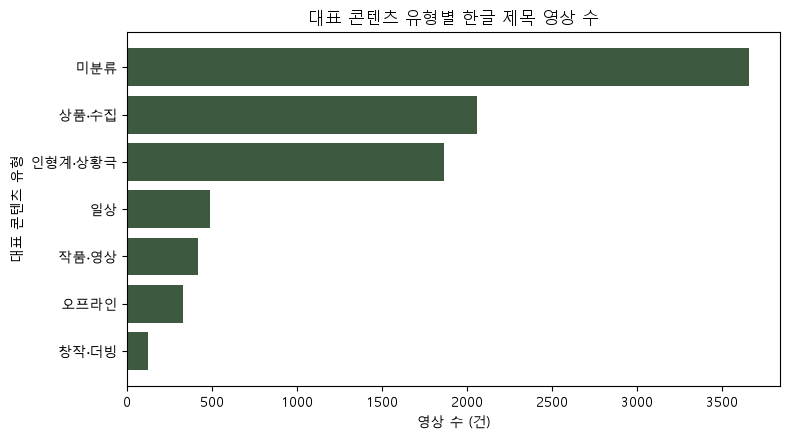

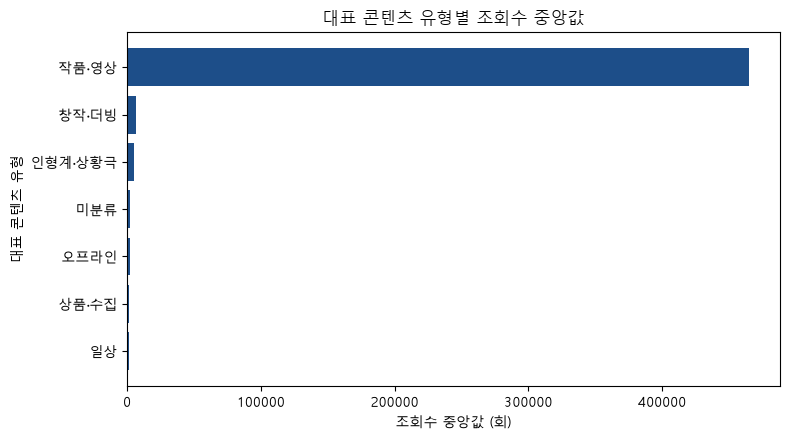

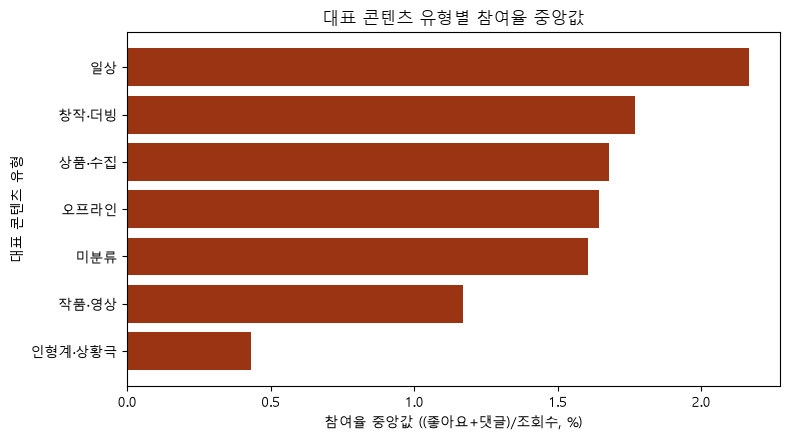

In [9]:
def summarize_group(frame, column):
    out = frame.groupby(column, dropna=False).agg(
        영상수=("video_id", "size"),
        조회수_평균=("view_count", "mean"),
        조회수_중앙값=("view_count", "median"),
        좋아요율_중앙값=("like_rate", "median"),
        댓글률_중앙값=("comment_rate", "median"),
        참여율_중앙값=("engagement_rate", "median"),
        참여율_계산가능=("engagement_rate", "count"),
        길이초_중앙값=("duration_sec", "median"),
        쇼츠60초이하_비율=("is_short_60", "mean"),
    )
    return out.sort_values("영상수", ascending=False).round(3)

primary_summary = summarize_group(df_kr, "primary_content_type")
print("대표 유형")
print(primary_summary.to_string())

multi_rows = []
for name, _ in CONTENT_RULES:
    part = df_kr.loc[df_kr[f"type_{name}"]]
    multi_rows.append({
        "유형": name,
        "해당 영상 수": len(part),
        "조회수 중앙값": part["view_count"].median(),
        "참여율 중앙값": part["engagement_rate"].median(),
        "60초 이하 비율": part["is_short_60"].mean(),
    })
untyped = df_kr.loc[df_kr["content_type"].isna()]
multi_rows.append({
    "유형": "미분류",
    "해당 영상 수": len(untyped),
    "조회수 중앙값": untyped["view_count"].median(),
    "참여율 중앙값": untyped["engagement_rate"].median(),
    "60초 이하 비율": untyped["is_short_60"].mean(),
})
multi_summary = pd.DataFrame(multi_rows).round(3)
print("\n복수 라벨 허용")
print(multi_summary.to_string(index=False))

order = primary_summary.sort_values("영상수", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order.index.astype(str), order["영상수"], color="#3d5a40")
ax.set_title("대표 콘텐츠 유형별 한글 제목 영상 수")
ax.set_xlabel("영상 수 (건)")
ax.set_ylabel("대표 콘텐츠 유형")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = primary_summary.sort_values("조회수_중앙값", ascending=True)
ax.barh(plot_df.index.astype(str), plot_df["조회수_중앙값"], color="#1d4e89")
ax.set_title("대표 콘텐츠 유형별 조회수 중앙값")
ax.set_xlabel("조회수 중앙값 (회)")
ax.set_ylabel("대표 콘텐츠 유형")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = primary_summary.sort_values("참여율_중앙값", ascending=True)
ax.barh(plot_df.index.astype(str), plot_df["참여율_중앙값"], color="#9a3412")
ax.set_title("대표 콘텐츠 유형별 참여율 중앙값")
ax.set_xlabel("참여율 중앙값 ((좋아요+댓글)/조회수, %)")
ax.set_ylabel("대표 콘텐츠 유형")
fig.tight_layout()
plt.show()


## 분석 3. 캐릭터별 콘텐츠 반응

질문: 어떤 캐릭터가 언급된 영상에서 반응이 상대적으로 높은가?

집계 단위는 영상-캐릭터 언급이다. 한 영상에 캐릭터가 여러 명이면 각 캐릭터 행에 모두 포함되므로, 캐릭터별 영상 수의 합은 고유 영상 수보다 크다. 언급은 선호와 같지 않다.


           언급영상수   조회수_중앙값  좋아요율_중앙값  댓글률_중앙값  참여율_중앙값  참여율_계산가능
character                                                       
하치와레        1346    4355.5     1.580    0.050    1.666      1252
우사기         1142    4123.5     1.520    0.042    1.616      1067
모몽가          378    5133.5     1.537    0.039    1.693       356
쿠리만쥬         233    3178.0     1.521    0.047    1.634       222
랏코           211    3015.0     1.565    0.043    1.694       198
시사           119   11133.0     1.451    0.044    1.593       110
카니            54    3688.5     1.035    0.080    1.166        49
아노코           32   22545.0     1.330    0.031    1.386        32
파자마파티즈        19   76091.0     1.462    0.045    1.471        15
데카츠요          11  432077.0     1.091    0.034    1.131        11
갑옷씨            7    1565.0     1.587    0.190    1.619         5

특정 캐릭터 언급이 없는 영상 6957
작품명 치이카와 포함 8811 / 먼작귀 2978


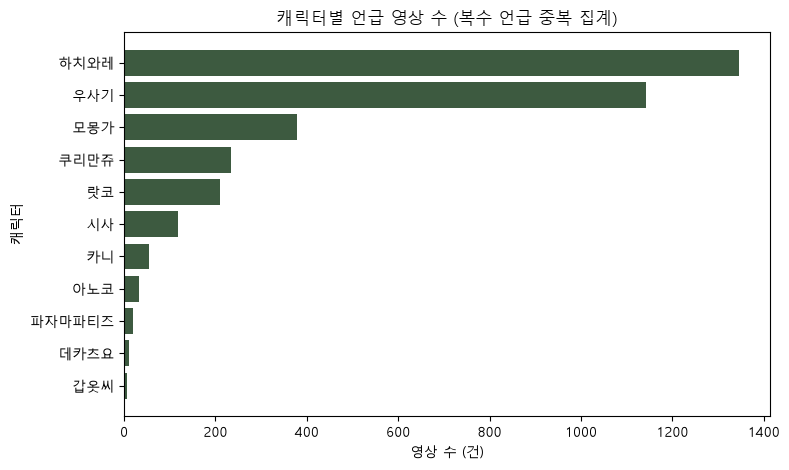

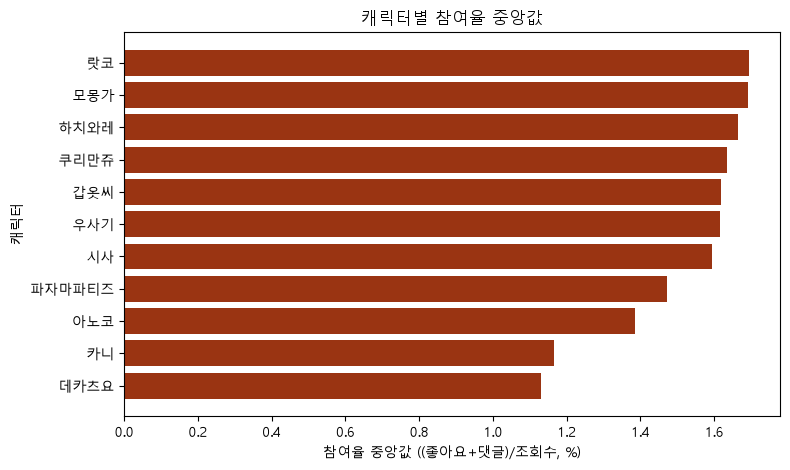

In [10]:
char_frames = []
for name, _ in CHARACTER_RULES:
    part = df_kr.loc[df_kr[f"char_{name}"], ["video_id", "view_count", "like_rate", "comment_rate", "engagement_rate"]].copy()
    part["character"] = name
    char_frames.append(part)
char_long = pd.concat(char_frames, ignore_index=True)
char_summary = char_long.groupby("character").agg(
    언급영상수=("video_id", "size"),
    조회수_중앙값=("view_count", "median"),
    좋아요율_중앙값=("like_rate", "median"),
    댓글률_중앙값=("comment_rate", "median"),
    참여율_중앙값=("engagement_rate", "median"),
    참여율_계산가능=("engagement_rate", "count"),
).sort_values("언급영상수", ascending=False).round(3)
print(char_summary.to_string())
print("\n특정 캐릭터 언급이 없는 영상", int(df_kr["character"].isna().sum()))
print("작품명 치이카와 포함", int(df_kr["series_치이카와"].sum()), "/ 먼작귀", int(df_kr["series_먼작귀"].sum()))

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_df = char_summary.sort_values("언급영상수", ascending=True)
ax.barh(plot_df.index, plot_df["언급영상수"], color="#3d5a40")
ax.set_title("캐릭터별 언급 영상 수 (복수 언급 중복 집계)")
ax.set_xlabel("영상 수 (건)")
ax.set_ylabel("캐릭터")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_df = char_summary.sort_values("참여율_중앙값", ascending=True)
ax.barh(plot_df.index, plot_df["참여율_중앙값"], color="#9a3412")
ax.set_title("캐릭터별 참여율 중앙값")
ax.set_xlabel("참여율 중앙값 ((좋아요+댓글)/조회수, %)")
ax.set_ylabel("캐릭터")
fig.tight_layout()
plt.show()


## 분석 4. 채널 구조

질문: 영상이 소수 채널에 몰려 있는가, 여러 채널에서 만들어지는가?

구독자 수는 수집되지 않았다. 채널 규모를 통제한 영향력은 이 데이터로 계산할 수 없다.


고유 채널 수 4168
채널당 게시 수 중앙값 1.0 / 평균 2.14
영상 1개만 올린 채널 비율 0.723
조회수 상위 10채널의 조회수 비중 0.616
조회수 상위 10채널의 영상 수 비중 0.072
        channel  게시수       누적조회수
Antistress Toys   98 335079386.0
         AniBox  383 176401890.0
         NekYos   18  46225606.0
  Favorite Toys   76  42312253.0
           성우전쟁   18  26081092.0
            마금이   12  16155403.0
            C급쇼   10  15696541.0
             조이    6  15292461.0
            쇼도독    4  14645348.0
         오늘은뭐볼까   16  14423423.0

연도별 신규 채널 수
year
2022     155
2023     556
2024     947
2025    1417
2026    1093


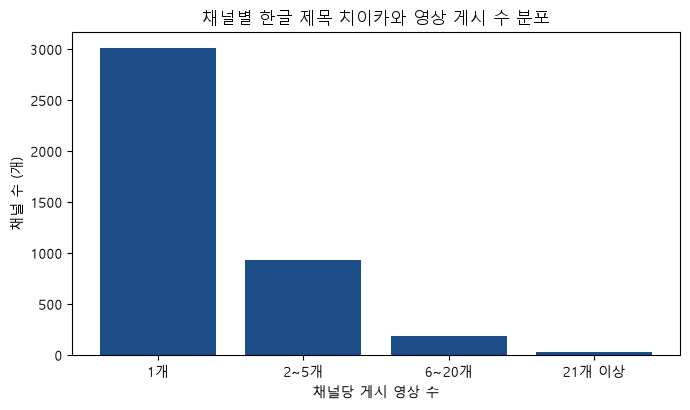

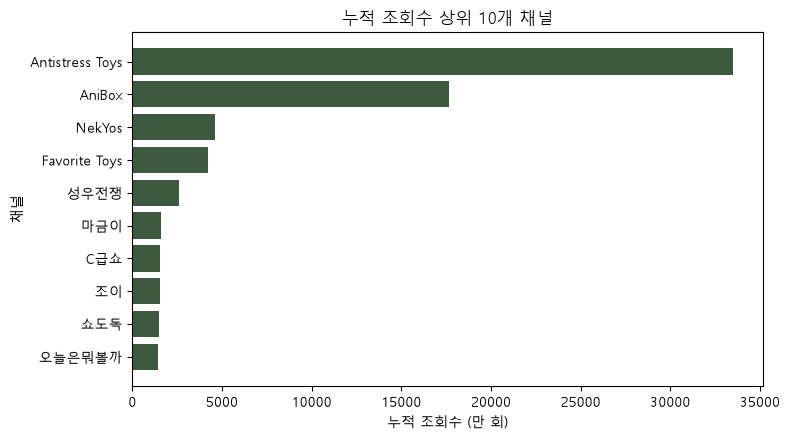

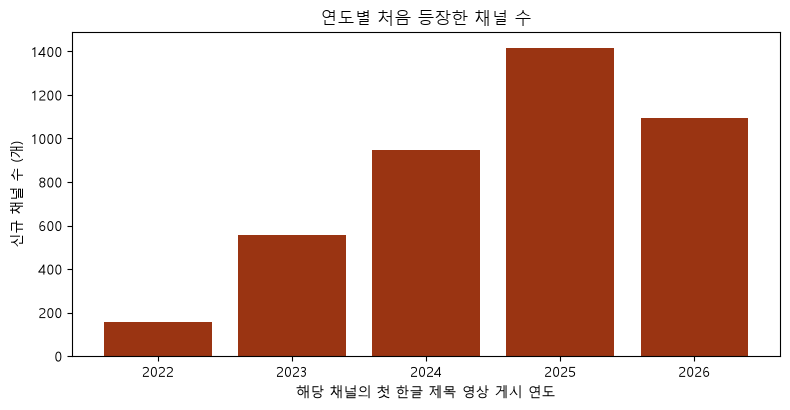

In [11]:
channel_stats = df_kr.groupby(["channel_id", "channel"]).agg(
    게시수=("video_id", "size"),
    누적조회수=("view_count", "sum"),
).reset_index()
n_channels = channel_stats["channel_id"].nunique()
n_videos = len(df_kr)
total_views = df_kr["view_count"].sum()

top10 = channel_stats.sort_values("누적조회수", ascending=False).head(10)
top10_view_share = top10["누적조회수"].sum() / total_views
top10_video_share = top10["게시수"].sum() / n_videos
one_video_share = (channel_stats["게시수"] == 1).mean()

print("고유 채널 수", n_channels)
print("채널당 게시 수 중앙값", channel_stats["게시수"].median(), "/ 평균", round(channel_stats["게시수"].mean(), 2))
print("영상 1개만 올린 채널 비율", round(one_video_share, 3))
print("조회수 상위 10채널의 조회수 비중", round(top10_view_share, 3))
print("조회수 상위 10채널의 영상 수 비중", round(top10_video_share, 3))
print(top10[["channel", "게시수", "누적조회수"]].to_string(index=False))

first_year = df_kr.groupby("channel_id")["year"].min()
new_channels = first_year.value_counts().sort_index().rename("신규 채널 수")
print("\n연도별 신규 채널 수")
print(new_channels.to_string())

bins = pd.cut(channel_stats["게시수"], bins=[0, 1, 5, 20, channel_stats["게시수"].max()], labels=["1개", "2~5개", "6~20개", "21개 이상"])
dist = bins.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(dist.index.astype(str), dist.values, color="#1d4e89")
ax.set_title("채널별 한글 제목 치이카와 영상 게시 수 분포")
ax.set_xlabel("채널당 게시 영상 수")
ax.set_ylabel("채널 수 (개)")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
top_plot = top10.sort_values("누적조회수", ascending=True)
ax.barh(top_plot["channel"], top_plot["누적조회수"] / 10000, color="#3d5a40")
ax.set_title("누적 조회수 상위 10개 채널")
ax.set_xlabel("누적 조회수 (만 회)")
ax.set_ylabel("채널")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(new_channels.index.astype(str), new_channels.values, color="#9a3412")
ax.set_title("연도별 처음 등장한 채널 수")
ax.set_xlabel("해당 채널의 첫 한글 제목 영상 게시 연도")
ax.set_ylabel("신규 채널 수 (개)")
fig.tight_layout()
plt.show()


## 원본 무결성 확인


In [12]:
assert df_merged.shape == original_analysis_shape
assert df_relevance_audit.shape == original_audit_shape
assert df_merged["video_id"].tolist() == original_analysis_ids
assert df_relevance_audit["video_id"].tolist() == original_audit_ids
assert df_merged["like_count"].isna().sum() == 743
assert df_merged["comment_count"].isna().sum() == 1265
print("원본 데이터프레임 행, 열, video_id 순서, 좋아요·댓글 결측 수 유지")
print("분석용 df", df.shape, "/ 국내 df_kr", df_kr.shape, "/ 제외 df_excluded", df_excluded.shape)


원본 데이터프레임 행, 열, video_id 순서, 좋아요·댓글 결측 수 유지
분석용 df (13383, 28) / 국내 df_kr (8941, 52) / 제외 df_excluded (1284, 8)
